# Lesson 7: Settling study and power sweep

Start with the physical key ON, laser ON, shutter closed, and the operator's
cooling, interlock and beam-path checks complete. This notebook does not enable
or reset the laser. Both runs finish with the shutter closed and laser still ON.

Run the settling study at the first approved setting, review it, then choose
SWEEP_DWELL_S and sweep the settings. Each sweep setting produces one settled row.

Stop on an error. Inspect laser.last_transaction and use the physical abort
procedure when needed. No retries or cleanup writes are automatic.

## 1. Settings

Use approved setpoints in 0.01 W increments and a site power ceiling.
`SETTLING_SAMPLE_COUNT` is the number of readings in the first-setpoint settling
trace. `SETTLING_SAMPLE_PAUSE_S` adds a pause after acquisition and readiness
checks, so the actual sample spacing is longer. Choose `SWEEP_DWELL_S` after
reviewing the trace: it is the wait after each sweep setpoint change, before reading.

With `prompt_enabled=True`, the controller reads the reply through CR/LF, then
consumes the enabled trailing prompt before sending another instruction. The
instrument prompt must already be enabled; construction sends no echo or prompt
changes. Matching instruction echoes and recognized leading notices are removed
from `read()` payloads while their received bytes remain in transaction evidence.

`TIMEOUT_S` configures serial write and receive waits. A reply line, each leading
notice and the trailing prompt use separate `read_until()` calls with that
configured timeout; there is no combined transaction deadline. No extra pause
is inserted between queries. Restart the kernel after a package update.

In [1]:
PORT = "COM5"
MODEL = "V2"
BAUDRATE = 19200
TIMEOUT_S = 2.0
SETPOINTS_W = [0.1, 0.2, 0.5, 0.75, 1.0, 1.5, 2.0]  # Approved points, in 0.01 W increments.
POWER_LIMIT_W = 2.0  # Site-approved ceiling in watts.
# Fixed-setpoint settling trace: number of readings and extra pause.
SETTLING_SAMPLE_COUNT = 20  # At least 2 readings.
SETTLING_SAMPLE_PAUSE_S = 0.5  # Extra pause after acquisition/readiness checks (s).

SWEEP_DWELL_S = 2  # Wait after each sweep setpoint change before reading (s).

## 2. Create the controller

Construction sends nothing. Check all power points before opening the port.
The API validates the ceiling and 0.01 W increments.

In [2]:
from datetime import UTC, datetime
from time import monotonic, sleep

from coherent_verdi import VerdiController
from coherent_verdi.controller import finite_range, validate_power_w

if PORT == "<PORT>" or POWER_LIMIT_W is None or not SETPOINTS_W:
    raise ValueError("Fill in the settings in section 1 first.")
laser = VerdiController(
    PORT,
    model=MODEL,
    baudrate=BAUDRATE,
    timeout_s=TIMEOUT_S,
    allow_writes=True,
    power_limit_w=POWER_LIMIT_W,
    prompt_enabled=True,
)
targets = [validate_power_w(watts, laser.power_limit_w) for watts in SETPOINTS_W]
if type(SETTLING_SAMPLE_COUNT) is not int or not 2 <= SETTLING_SAMPLE_COUNT <= 10000:
    raise ValueError("SETTLING_SAMPLE_COUNT must be an integer from 2 to 10000.")
SETTLING_SAMPLE_PAUSE_S = finite_range(
    SETTLING_SAMPLE_PAUSE_S, 0.001, 3600, "SETTLING_SAMPLE_PAUSE_S"
)
print("Power points / W:", targets)

study_complete = False


def check_ready(target=None, *, shutter_open=False):
    expected = {
        "?K": 1,
        "?L": 1,
        "?S": int(shutter_open),
        "?F": [],
        "?M": 1,
        "?D1SS": 1,
        "?LBOSS": 1,
        "?ESS": 1,
        "?VSS": 1,
    }
    if target is not None:
        expected["?SP"] = target
    for query, value in expected.items():
        actual = laser.get_value(query)
        if actual != value:
            raise RuntimeError(f"Readiness changed: {query} expected {value!r}, got {actual!r}")

Power points / W: [0.1, 0.2, 0.5, 0.75, 1.0, 1.5, 2.0]


## 3. Open the serial port

Close other serial owners first. Run this cell alone and inspect the result.
True means the local port opened; communication starts in section 4.

In [3]:
connected = laser.connect(override=False)
print("Serial port open:", connected)

Serial port open: True


## 4. Read the instrument details

Purge host queues once, then read firmware, operating hours and fault history.

In [4]:
from pprint import pprint

laser.purge_buffers()
baseline = laser.get_diagnostics()
pprint(baseline)

{'diode_hours': 2390123.54,
 'fault_history': [],
 'head_hours': 2694.91,
 'power_supply_hours': 2694.91,
 'software_version': '6.05'}


## 5. Prepare the study

With the laser already ON and shutter closed, type STUDY to store the first
setpoint. Verify readiness and the stored value before opening the shutter.

In [5]:
if input("Type STUDY to prepare the approved first setpoint: ").strip() != "STUDY":
    raise RuntimeError("Cancelled.")
check_ready()
samples = []
time_samples = []
study_complete = False
laser.set_power_w(targets[0])
check_ready(targets[0])
print("First setpoint verified; laser ON, shutter closed.")

First setpoint verified; laser ON, shutter closed.


## 6. Settling study

Open once, record power/current pairs with timestamps, then close. Readiness is
checked before accepting each pair. The read-window duration excludes those checks.
This measures shutter-opening response at the first setting, not every later
power-step transition. The pause is added to the serial acquisition time.

The saved 2026-10-27 run below stopped on a firmware `level0 set!` notice.
The updated driver recognizes that exact notice and still requires a separate
reading and the expected prompt. Restart the kernel after updating the driver.
Saved outputs preserve the original failure; the fix has only fake-serial validation.

In [6]:
study_complete = False
check_ready(targets[0])
laser.set_shutter(open=True)
study_started = monotonic()
if laser.get_value("?S") != 1:
    raise RuntimeError("Shutter opening not confirmed.")
for index in range(SETTLING_SAMPLE_COUNT):
    sample_started = monotonic()
    row = {
        "sampled_at_utc": datetime.now(UTC).isoformat(),
        "elapsed_s": sample_started - study_started,
        "target_w": targets[0],
        "reported_power_w": laser.get_power_w(),
        "diode_current_a": laser.get_value("?D1C"),
    }
    row["sample_duration_s"] = monotonic() - sample_started
    check_ready(targets[0], shutter_open=True)
    time_samples.append(row)
    print(row)
    if index + 1 < SETTLING_SAMPLE_COUNT:
        sleep(SETTLING_SAMPLE_PAUSE_S)

laser.set_shutter(open=False)
check_ready(targets[0])
study_complete = True
print("Settling study complete: laser ON, shutter closed. Review the trace before the sweep.")

{'sampled_at_utc': '2026-10-27T23:08:15.966765+00:00', 'elapsed_s': 0.03100000007543713, 'target_w': 0.1, 'reported_power_w': 0.025, 'diode_current_a': 11.87, 'sample_duration_s': 0.06199999991804361}
{'sampled_at_utc': '2026-10-27T23:08:16.837243+00:00', 'elapsed_s': 0.9060000000754371, 'target_w': 0.1, 'reported_power_w': 0.114, 'diode_current_a': 12.87, 'sample_duration_s': 0.06199999991804361}
{'sampled_at_utc': '2026-10-27T23:08:17.709567+00:00', 'elapsed_s': 1.7810000000754371, 'target_w': 0.1, 'reported_power_w': 0.114, 'diode_current_a': 12.83, 'sample_duration_s': 0.06199999991804361}
{'sampled_at_utc': '2026-10-27T23:08:18.620001+00:00', 'elapsed_s': 2.687000000034459, 'target_w': 0.1, 'reported_power_w': 0.114, 'diode_current_a': 12.81, 'sample_duration_s': 0.06299999996554106}
{'sampled_at_utc': '2026-10-27T23:08:19.490828+00:00', 'elapsed_s': 3.562000000034459, 'target_w': 0.1, 'reported_power_w': 0.114, 'diode_current_a': 12.79, 'sample_duration_s': 0.06299999996554106}
{

## 7. Plot the study (optional)

Run this cell with Matplotlib installed. Plot elapsed time at the start of each
sequential power/current pair. After review, set an approved SWEEP_DWELL_S in section 1
and rerun only that settings cell before section 8.

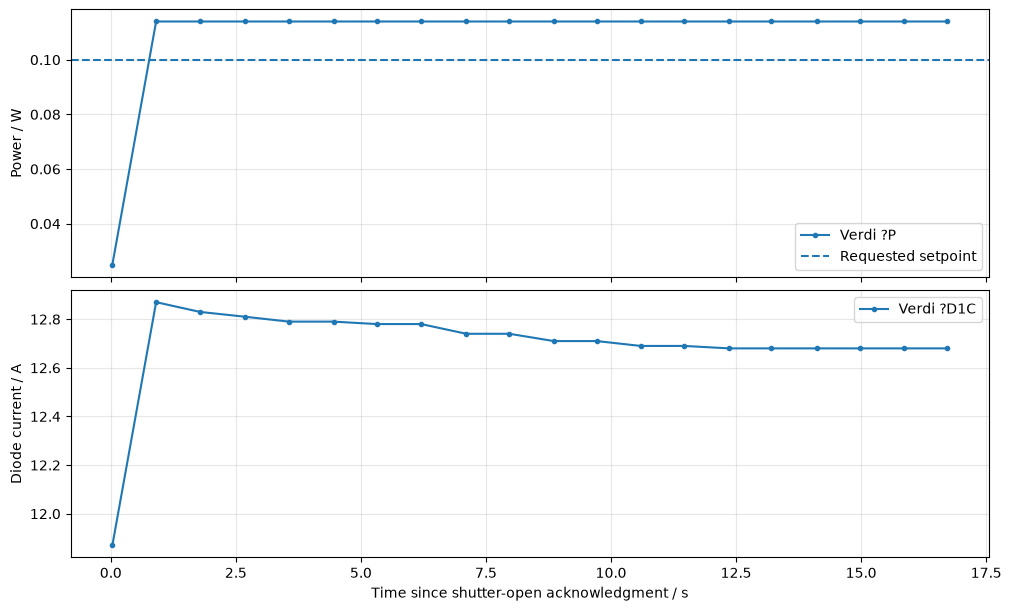

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, constrained_layout=True)
times = [row["elapsed_s"] for row in time_samples]
axes[0].plot(times, [row["reported_power_w"] for row in time_samples], ".-", label="Verdi ?P")
axes[0].axhline(targets[0], linestyle="--", label="Requested setpoint")
axes[0].set(ylabel="Power / W")
axes[1].plot(times, [row["diode_current_a"] for row in time_samples], ".-", label="Verdi ?D1C")
axes[1].set(xlabel="Time since shutter-open acknowledgment / s", ylabel="Diode current / A")
for axis in axes:
    axis.grid(alpha=0.3)
    axis.legend()
plt.show()

## 8. Power sweep

After the completed study, type SWEEP. Each point is: check readiness, set power,
wait SWEEP_DWELL_S, read one row, verify readiness. Close the shutter at the end;
leave the laser ON. There are no keyboard prompts while the shutter is open.

In [8]:
if not study_complete:
    raise RuntimeError("Complete the settling study in section 6 before the power sweep.")
SWEEP_DWELL_S = finite_range(SWEEP_DWELL_S, 0.001, 3600, "SWEEP_DWELL_S")
if input("Type SWEEP to run the approved settings: ").strip() != "SWEEP":
    raise RuntimeError("Cancelled.")
check_ready(targets[0])
laser.set_shutter(open=True)
sweep_started = monotonic()

for target in targets:
    check_ready(shutter_open=True)
    laser.set_power_w(target)
    sleep(SWEEP_DWELL_S)
    sample_started = monotonic()
    row = {
        "target_w": target,
        "reported_power_w": laser.get_power_w(),
        "diode_current_a": laser.get_value("?D1C"),
        "diode_temp_c": laser.get_value("?D1T"),
        "heatsink_temp_c": laser.get_value("?D1HST"),
        "elapsed_s": sample_started - sweep_started,
    }
    check_ready(target, shutter_open=True)
    samples.append(row)
    print(row)

laser.set_shutter(open=False)
check_ready(targets[-1])
print("Sweep complete: shutter CLOSED, laser ON.")

{'target_w': 0.1, 'reported_power_w': 0.114, 'diode_current_a': 12.79, 'diode_temp_c': 27.89, 'heatsink_temp_c': 24.92, 'elapsed_s': 2.2969999999040738}
{'target_w': 0.2, 'reported_power_w': 0.213, 'diode_current_a': 13.09, 'diode_temp_c': 27.89, 'heatsink_temp_c': 24.93, 'elapsed_s': 5.077999999979511}
{'target_w': 0.5, 'reported_power_w': 0.507, 'diode_current_a': 13.55, 'diode_temp_c': 27.89, 'heatsink_temp_c': 24.93, 'elapsed_s': 7.827999999979511}
{'target_w': 0.75, 'reported_power_w': 0.754, 'diode_current_a': 13.73, 'diode_temp_c': 27.89, 'heatsink_temp_c': 24.93, 'elapsed_s': 10.686999999918044}
{'target_w': 1.0, 'reported_power_w': 1.001, 'diode_current_a': 13.86, 'diode_temp_c': 27.91, 'heatsink_temp_c': 24.95, 'elapsed_s': 13.530999999959022}
{'target_w': 1.5, 'reported_power_w': 1.495, 'diode_current_a': 14.18, 'diode_temp_c': 27.92, 'heatsink_temp_c': 24.95, 'elapsed_s': 16.280999999959022}
{'target_w': 2.0, 'reported_power_w': 1.99, 'diode_current_a': 14.79, 'diode_temp_c

## 9. Save results

Write the study and sweep to one CSV, with a `stage` column (`study` or `sweep`).
`elapsed_s` is relative to the start of its stage. Fields not acquired for a stage
are blank: study rows have timestamps/read durations; sweep rows have temperatures.
Collected rows can also be saved after an error, once the physical situation has
been handled. The saved two-path output below belongs to the earlier save code;
the revised cell writes one file.

In [9]:
import csv
from pathlib import Path

csv_rows = [
    {"stage": stage, **row}
    for stage, rows in (("study", time_samples), ("sweep", samples))
    for row in rows
]
csv_path = None
if csv_rows:
    stamp = datetime.now(UTC).strftime("%Y%m%dT%H%M%S_%fZ")
    csv_path = Path(f"verdi_sweep_{stamp}.csv")
    fields = [
        "stage",
        "sampled_at_utc",
        "elapsed_s",
        "target_w",
        "reported_power_w",
        "diode_current_a",
        "diode_temp_c",
        "heatsink_temp_c",
        "sample_duration_s",
    ]
    with csv_path.open("x", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=fields)
        writer.writeheader()
        writer.writerows(csv_rows)
    print("Saved:", csv_path.resolve())
else:
    print("No samples to save.")

Saved: C:\repo\coherent-verdi-control\examples\verdi_sweep_20261027T230916_196976Z.csv


## 10. Plot the sweep (optional)

With Matplotlib installed, plot the settled power and diode current against
setpoint. The dashed line is requested power. These cells use only collected data.

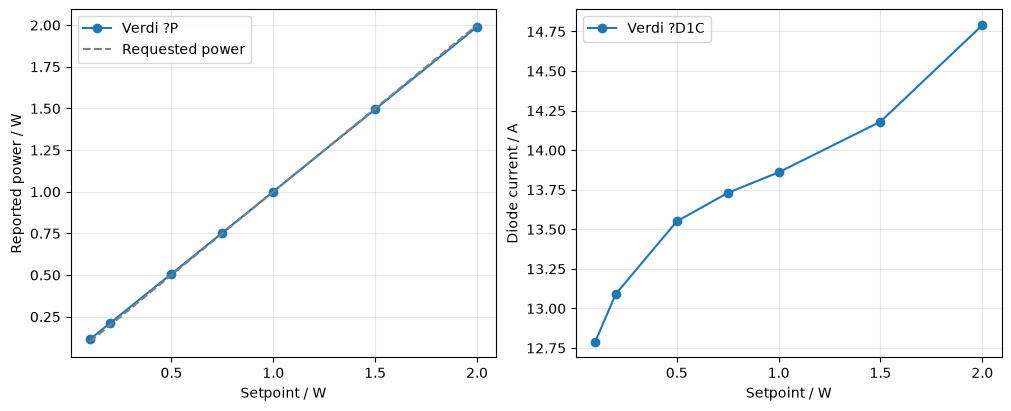

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
setpoints = [row["target_w"] for row in samples]
axes[0].plot(setpoints, [row["reported_power_w"] for row in samples], "o-", label="Verdi ?P")
axes[0].plot(setpoints, setpoints, "--", color="0.5", label="Requested power")
axes[0].set(xlabel="Setpoint / W", ylabel="Reported power / W")
axes[1].plot(setpoints, [row["diode_current_a"] for row in samples], "o-", label="Verdi ?D1C")
axes[1].set(xlabel="Setpoint / W", ylabel="Diode current / A")
for axis in axes:
    axis.locator_params(axis="x", nbins=5)
    axis.grid(alpha=0.3)
    axis.legend()
plt.show()

## 11. Disconnect

Release the serial port. This sends no commands; the laser remains ON.

In [11]:
laser.disconnect()